# From reusable inputs to a controlled representation benchmark

How many requests must run, what will the features contain, and which experiments test their value? This notebook distinguishes **measured input counts**, **approximate full-run cost scenarios**, **recorded diagnostic usage** and **planned fits**. None is a downstream accuracy result. No API call, encoder, PCA fit or predictive model runs here.


Audit: Fake Job Postings


Audit: Jigsaw Toxicity


Audit: Kickstarter


Audit: Data Scientist Salary


Audit: Michelin Guide


...

Audit: SciMagojr Impact


Audit: Vancouver Salaries


Audit: Video Games Sales


Audit: Zomato Restaurants


dataset,task_type,rows,text_columns,per_column,joint,main_features_both,combined_unique_inputs
Fake Job Postings,binary_classification,12725,3,3,1,4,34631
Jigsaw Toxicity,binary_classification,100000,1,1,1,1,99661
Kickstarter,binary_classification,86502,3,3,1,4,345321
Data Scientist Salary,multiclass_classification,15841,5,30,6,36,42668
Michelin Guide,multiclass_classification,18843,6,30,5,35,82599
Product Sentiment,multiclass_classification,5091,1,4,4,4,5084
US Accidents,multiclass_classification,100001,6,24,4,28,266975
Wine Review,multiclass_classification,84123,2,60,30,90,158319
Women's Clothing,multiclass_classification,18788,2,10,5,15,45326
Baby Products,regression,5085,4,4,1,5,10519


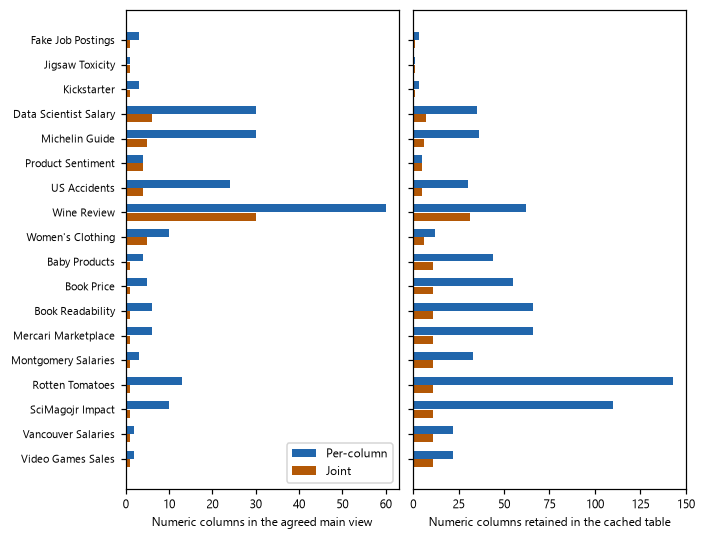

In [1]:
import sys
from pathlib import Path
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "src").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
import copy
import json
import pandas as pd
import matplotlib.pyplot as plt
from src.utils.config import load_config, save_resolved_config
from src.utils.notebook_display import display_local, display_json, display_table
from src.utils.notebook_report import begin_report, report_section, record, finish_report
from src.data.audit import audit_collection
from src.visualize import figures, style
style.apply()

from src.jev.features import feature_plan, table_schemas
from src.jev.presentation import scope_table, dataset_budget, mode_budget, throughput_table
from src.jev.review import review_collection, review_totals
from src.visualize.feature_design import feature_dimensions_figure, request_counts_figure, workload_figure
from src.visualize.build_review import extraction_figure
NOTEBOOK = "2. feature_creation/03_feature_creation"
begin_report()
report_section("1. The selected dataset and feature scope")
save = figures.FigureSaver(NOTEBOOK)
cfg = load_config("feature_creation")
save_resolved_config(cfg, NOTEBOOK)
audit = audit_collection(cfg)
plan = feature_plan(audit, cfg)
scope = scope_table(audit, plan)
display_local(scope)
fig, name, caption = feature_dimensions_figure(plan)
save(fig, name, caption=caption)
display_local(fig)
plt.close(fig)
record(plan, "Complete retained and main feature dimensions")


## 2. Count unique requests, not rows × text columns

Repeated exact text in the same named column shares a complete request. Joint reuse requires all named available text to match. Single-available-field joint inputs reuse the matching per-column input.

For the selected 18 datasets, the character-based budget uses the **active saved documented questions**, including task definitions, choices and field meanings. These are approximate API-body tokens, not Jev billing counts. Excluded datasets remain an audit-only reference using the earlier accepted wording, so their cost difference is a scope illustration, not an exact matched-version bill. Provider overhead and retries remain separate.


Reviewed Fake Job Postings


Reviewed Jigsaw Toxicity


Reviewed Kickstarter


Reviewed Data Scientist Salary


Reviewed Michelin Guide


...

Reviewed SciMagojr Impact


Reviewed Vancouver Salaries


Reviewed Video Games Sales


Reviewed Zomato Restaurants


mode,unique_requests,input_tokens_approx,cost_usd
per_column,1184937,499951428,20.997960
joint,620425,316849443,13.307677
both,1698127,784919303,32.966611


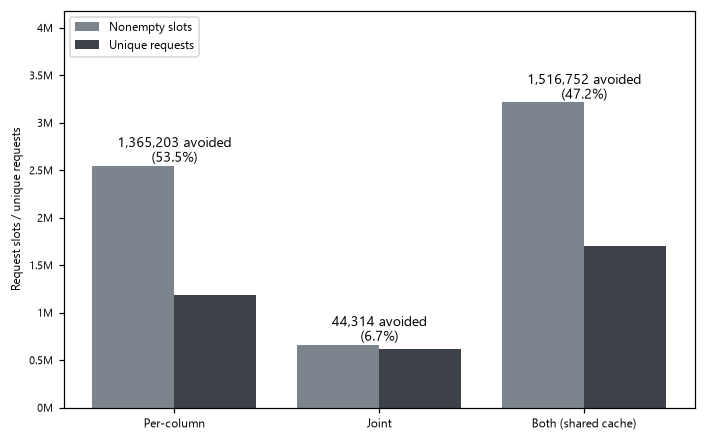

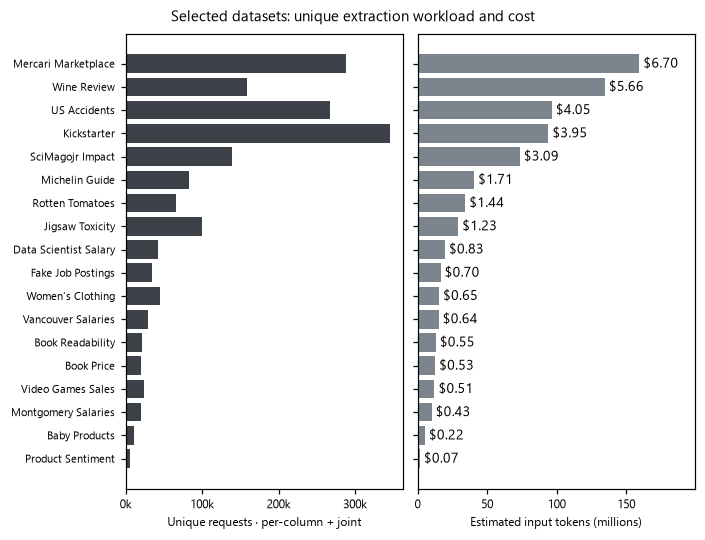

In [2]:
report_section("2. Actual duplicate-aware extraction workload")
all_estimates, pilot_preview = review_collection(cfg, include_excluded=True)
excluded = cfg["dataset_selection"]["exclude"]
estimates = all_estimates[~all_estimates.dataset_id.isin(excluded)].copy()
mode_totals = mode_budget(estimates, cfg)
display_local(mode_totals)
selected_summary = audit.summary[~audit.summary.dataset_id.isin(excluded)]
fig, name, caption = request_counts_figure(selected_summary)
save(fig, name, caption=caption)
display_local(fig)
plt.close(fig)
by_dataset = dataset_budget(estimates)
fig, name, caption = extraction_figure(by_dataset, cfg["cost"]["input_price_per_million"])
save(fig, name, caption=caption)
display_local(fig)
plt.close(fig)
record(by_dataset, "Dataset counts and approximate input tokens")
record(estimates, "Complete group-level budget and tokenizer sensitivity")

record({"selected_questions": "Saved prepared input version, including definitions of nonempty fields", "removed_dataset_reference": "Audit-only accepted templates; no extraction planned"}, "Budget question provenance")


## 2.1 Exact tokenizer counts and the earlier context screen

The Experiment 0 audit counts every nonempty separate and joint input in the **18 selected datasets**, after exact duplicate reuse. When its saved results are available, the first table below shows **actual tokenizer counts including the complete publisher formatting** for the five selected open-weight models. It verifies that the saved input files still match the counted versions. GPU runtime parity remains a pilot check. All five selected open-weight providers are audited with their actual tokenizers. Jev uses a separately reviewed hosted context envelope; Microsoft is excluded.

The older screen divides the shared state/question JSON length by 3, 4 or 5. **Those estimates are neither actual counts nor safe upper bounds** and omit publisher formatting. Four warnings refer to four unique inputs, not necessarily four different rows. They do not establish a context overflow; the exact counts take precedence for the tested models.

Before inference, every complete provider-formatted input must fit its deployed context limit. Overflow stops the request without truncation or row removal. Any shortening would require one reviewed, deterministic policy shared by all models and a new input/cache version. Empty text is missing; an overlong input is not empty text.

In [3]:
report_section("2.1 Exact tokenizer audit and historical approximate screen")
from src.cluster.token_audit import saved_exact_token_tables
exact_scope, exact_counts = saved_exact_token_tables()
record(exact_scope, "Exact tokenizer audit scope and remaining hosted checks")
print(exact_scope)
display_local(exact_counts)

from src.jev.context import saved_screen_tables
context_scope, context_scenarios, context_origins = saved_screen_tables()
record(context_scope, "Historical approximate screen; not confirmed overflows")
display_local(context_scenarios)
display_local(context_origins)
print("Use the exact-count table for the tested open models. Hosted counts and real GPU response behavior remain unverified; approximate warnings alone are not grounds to delete rows.")

{'status': 'not_counted', 'command': 'python -m src.cluster.token_audit'}


Use the exact-count table for the tested open models. Hosted counts and real GPU response behavior remain unverified; approximate warnings alone are not grounds to delete rows.


## 3. Cost uncertainty and the effect of removing Zomato and Spotify

Price: **$0.042 per million input tokens**, confirmed in TypeSafe's reply and current documentation. Character/token scenarios are approximations, not quoted billing totals. Unknown billing overhead, retries and long-input policy can change the total.

Removing Zomato changes dataset coverage, so it remains visible in the audit and the exclusion is recorded before evaluating predictive performance.

characters_per_token,requests_for_combined_build,wire_tokens_combined_approx,cost_usd
3,1698127,1046290608,43.944206
4,1698127,784919303,32.966611
5,1698127,628106967,26.380493


mode,unique_requests,input_tokens_approx,cost_usd,scope
per_column,1401423,796345377,33.446506,"All 20, reference"
joint,738163,544374968,22.863749,"All 20, reference"
both,2032351,1308838777,54.971229,"All 20, reference"
per_column,1184937,499951428,20.997960,Selected 18
joint,620425,316849443,13.307677,Selected 18
both,1698127,784919303,32.966611,Selected 18


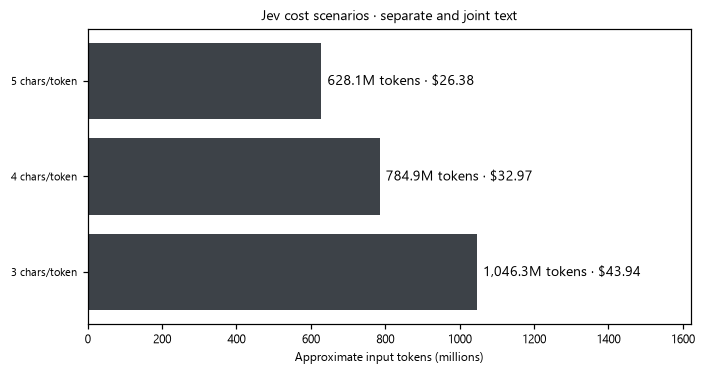

In [4]:
report_section("3. Costs, uncertainty and explicit exclusion")
sensitivity = review_totals(estimates, cfg)
display_local(sensitivity[["characters_per_token", "requests_for_combined_build", "wire_tokens_combined_approx", "cost_usd"]])
comparison = pd.concat([mode_budget(all_estimates, cfg).assign(scope="All 20, reference"), mode_totals.assign(scope="Selected 18")], ignore_index=True)
display_local(comparison)
fig, name, caption = workload_figure(sensitivity)
save(fig, name, caption=caption)
display_local(fig)
plt.close(fig)
central = mode_totals[mode_totals["mode"].eq("both")].iloc[0]
record({"price_per_million_usd": cfg["cost"]["input_price_per_million"], "central_cost_usd": central.cost_usd, "central_plus_10_percent_billed_retry_cost_usd": None if central.cost_usd is None else central.cost_usd * 1.10, "provider_overhead_not_measured": True}, "Cost caveats")


## 4. Account limits and achievable throughput

The owner confirmed **80 requests/second and 100,000 input tokens/second**. The table distinguishes ideal account-rate lower bounds from the current dispatcher's conservative token bound. Doubling RPS alone does not improve that dispatcher limit.

The pilot runs at 0.2 RPS with one worker. Current dispatch reserves 64,000 tokens per attempt, so even a higher RPS setting allows only 1.5625 starts/second at the current TPS limit, before latency. This bound protects accounting; approximate character counts cannot safely replace it. Ask TypeSafe for a supported token-count method or tighter guaranteed bounds, and clarify whether rate limiting charges actual tokens or reserved context. No paid high-throughput test or limit increase is enabled by this notebook.


In [5]:
report_section("4. Throughput and duration")
traffic = throughput_table(central.unique_requests, central.input_tokens_approx, cfg)
display_local(traffic.round(2))
record(cfg["throughput_review"], "Account limits and unmeasured planning assumptions")


scenario,requests_per_second,input_tokens_per_second,request_bound_hours,estimated_token_bound_hours,ideal_minimum_hours,current_dispatcher_minimum_hours,limitation
Current owner-confirmed account,80,100000,5.90,2.18,5.90,301.89,"Latency, workers, failures and other account traffic add time; token estimate is not exact"
Hypothetical double RPS only,160,100000,2.95,2.18,2.95,301.89,"Latency, workers, failures and other account traffic add time; token estimate is not exact"
Hypothetical 10x TPS only,80,1000000,5.90,0.22,5.90,30.19,"Latency, workers, failures and other account traffic add time; token estimate is not exact"


## 5. One permanent file per dataset

`data/jev_cache/<dataset_id>.sqlite3` contains:

- **responses:** one raw response per exact request/version; state, question, usage and timestamp.
- **origins:** dataset and source row IDs that reused each response.
- **feature_artifacts:** compressed numeric feature tables, row-to-request tables and immutable manifests for each representation/version.
- **dataset_identity:** prevents writing a different dataset into the file.

Row IDs are `csv:N`, the zero-based original CSV position, paired with the dataset fingerprint. Targets remain in the raw dataset. Missing inputs have missing numeric features and no request key. A completed per-column and joint build shares this one file.

Logs: `output_JEVPFN/2. feature_creation/logs/`. Compact completion indexes: `output_JEVPFN/2. feature_creation/manifests/`. No real dataset cache is created during this notebook. SQLite may create temporary journal files during writes; copy the file only after writers close.

One dataset file can contain multiple decision models and question versions. `feature_inventory(path)` lists them without loading large tables; `load_feature_selection(path, selector)` selects a provider, model/version, question bank and representation. All selected response decoders are implemented; real runtime validation and acceptance are still required before full extraction. The shared questions are prepared first in `1. question_preparation/01_prepare_questions.ipynb`.

Guarded dispatcher and persistent reservations are implemented but disabled. This notebook performs no extraction or model fitting. Next: Experiment 0A on VSC validates the self-hosted GPU runtimes; full feature creation follows acceptance, then Experiment 0B validates completed features before the benchmark. Hosted pilots remain local.


extractor,enabled,unique_requests,input_tokens_central_proxy,input_price_usd_per_million,hosted_cost_central_proxy_usd,context_tokens_reference,unique_requests_above_context_screen,above_context_screen_pct,readiness,cost_caveat
jev,False,1698127,784919303,0.042,32.966611,32000,0,0.000000,"disabled; account/checkpoint, context and live schema pilot required","proxy only; provider tokenizer, billing overhead/retries differ"
liquid,False,1698127,784919303,NaN,NaN,32768,0,0.000000,"disabled; account/checkpoint, context and live schema pilot required",self-hosted compute/storage unpriced
perplexity,False,1698127,784919303,NaN,NaN,8192,0,0.000000,"disabled; account/checkpoint, context and live schema pilot required",self-hosted compute/storage unpriced
cloudflare,False,1698127,784919303,NaN,NaN,16384,0,0.000000,"disabled; account/checkpoint, context and live schema pilot required",self-hosted compute/storage unpriced
intern,False,1698127,784919303,NaN,NaN,8192,0,0.000000,"disabled; account/checkpoint, context and live schema pilot required",self-hosted compute/storage unpriced
strands,False,1698127,784919303,NaN,NaN,4096,4,0.000236,"disabled; account/checkpoint, context and live schema pilot required",self-hosted compute/storage unpriced
h2o,False,1698127,784919303,NaN,NaN,32000,0,0.000000,"disabled; account/checkpoint, context and live schema pilot required",self-hosted compute/storage unpriced
sii,False,1698127,784919303,NaN,NaN,6000,0,0.000000,"disabled; account/checkpoint, context and live schema pilot required",self-hosted compute/storage unpriced
kev,False,1698127,784919303,NaN,NaN,65536,0,0.000000,"disabled; account/checkpoint, context and live schema pilot required",self-hosted compute/storage unpriced
decision3,False,1698127,784919303,NaN,NaN,32768,0,0.000000,"disabled; account/checkpoint, context and live schema pilot required",self-hosted compute/storage unpriced


dataset_id,stored_jobs,completed,attempts,unresolved_jobs,reserved_usd,recorded_charges_usd,reported_input_tokens,source,scope
BIN_TEXT_FAKE_JOB_POSTING,10,10,10,0,0.0,0.000460,10942,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\data\jev_cache\BIN_TEXT_FAKE_JOB_POSTING.sqlite3,cumulative stored Jev diagnostic jobs
BIN_TEXT_JIGSAW_TOXICITY,4,4,4,0,0.0,0.000104,2467,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\data\jev_cache\BIN_TEXT_JIGSAW_TOXICITY.sqlite3,cumulative stored Jev diagnostic jobs
BIN_TEXT_KICKSTARTER_FUNDING,13,13,13,0,0.0,0.000322,7664,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\data\jev_cache\BIN_TEXT_KICKSTARTER_FUNDING.sqlite3,cumulative stored Jev diagnostic jobs
MUL_TEXT_DATA_SCIENTIST_SALARY,19,19,19,0,0.0,0.000745,17728,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\data\jev_cache\MUL_TEXT_DATA_SCIENTIST_SALARY.sqlite3,cumulative stored Jev diagnostic jobs
MUL_TEXT_MICHELIN_RESTAURANTS,22,22,22,0,0.0,0.000800,19037,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\data\jev_cache\MUL_TEXT_MICHELIN_RESTAURANTS.sqlite3,cumulative stored Jev diagnostic jobs
MUL_TEXT_PRODUCT_SENTIMENT,4,4,4,0,0.0,0.000120,2862,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\data\jev_cache\MUL_TEXT_PRODUCT_SENTIMENT.sqlite3,cumulative stored Jev diagnostic jobs
MUL_TEXT_US_ACCIDENTS,22,22,22,0,0.0,0.000667,15877,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\data\jev_cache\MUL_TEXT_US_ACCIDENTS.sqlite3,cumulative stored Jev diagnostic jobs
MUL_TEXT_WINE_REVIEW,10,10,10,0,0.0,0.000780,18578,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\data\jev_cache\MUL_TEXT_WINE_REVIEW.sqlite3,cumulative stored Jev diagnostic jobs
dataset_id,stored_jobs,completed,attempts,unresolved_jobs,reserved_usd,recorded_charges_usd,reported_input_tokens,source,scope
BIN_TEXT_FAKE_JOB_POSTING,10,10,10,0,0.0,0.000460,10942,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\data\jev_cache\BIN_TEXT_FAKE_JOB_POSTING.sqlite3,cumulative stored Jev diagnostic jobs


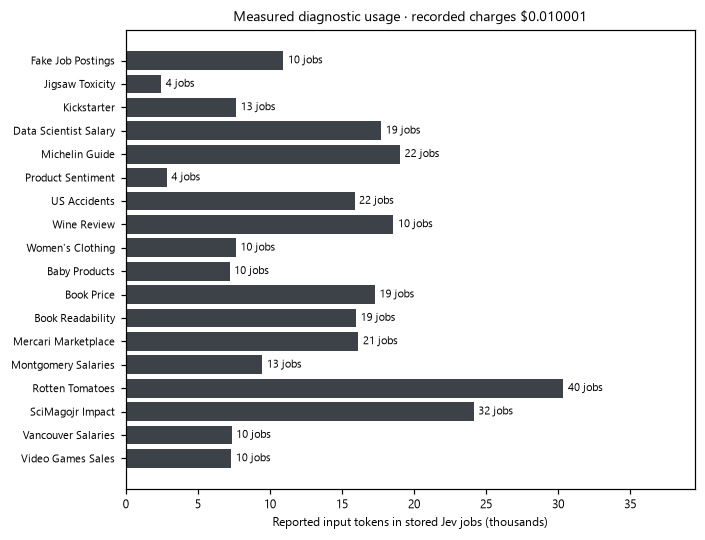

In [6]:
report_section("5. Permanent dataset storage and readiness")
record(table_schemas(), "Logical file/table contracts")
from src.utils import paths
record({"dataset_files": [str(paths.dataset_cache_path(dataset_id)) for dataset_id in plan.dataset_id.drop_duplicates()], "logs": str(paths.logs_dir("feature_creation")), "manifests": str(paths.manifests_dir("feature_creation")), "api_enabled": cfg["jev"]["enabled"], "feature_creation_enabled": cfg["feature_creation"]["enabled"], "model": cfg["jev"]["model"], "context_overflow_policy": cfg["feature_creation"]["context_overflow_policy"]}, "Build contract")
print("Guarded dispatcher and persistent reservations are implemented but disabled. This notebook performs no extraction or model fitting. Next: Experiment 0A on VSC validates the self-hosted GPU runtimes; full feature creation follows acceptance, then Experiment 0B validates completed features before the benchmark. Hosted pilots remain local.")

from src.utils.config import load_yaml
from src.jev.feasibility import comparison_feasibility
from src.jev.alternatives import preview
from src.jev.inspection import representative_requests
extractor_catalog = load_yaml("extractors")
feasibility = comparison_feasibility(estimates, extractor_catalog, cfg)
display_table("Provider feasibility assumptions (not live acceptance)", feasibility, preview_rows=0)
record(feasibility, "Eleven disabled extractors: cost and context screens, not quotes or live access tests")
shared_example = representative_requests(audit, cfg)[0]
record({provider: preview(shared_example, provider) for provider in extractor_catalog["candidates"]}, "Shared semantic question and provider-specific offline mapping")

from src.evaluation.notebook_evidence import measured_jev_usage
from src.visualize.research import measured_usage_figure
usage = measured_jev_usage()
display_table("Cumulative recorded Jev dataset-pilot usage (all retained job versions)", usage)
for fig, name, caption in measured_usage_figure(usage):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)


## 6. How the saved features enter the experiments

Experiment 1 compares non-text, joint, per-column and both decision features in six predictors. Experiment 2 compares three frozen encoders: E5-small, E5-large and Qwen3-Embedding-0.6B. Each uses per-column PCA32 and joint PCA256/128/64/32/16/8. Experiment 2 does not include decision features. Experiment 3 compares TabSTAR, ConTextTab and AG-MM on original text and non-text features. Winner-selected combinations belong only to descriptive/exploratory Experiment 5.

PCA is prepared on CPU once for each exact inner/outer training partition and reused across predictors. Non-text and decision columns never enter PCA. Validation/test rows only transform and have the same output columns. Missingness indicators are retained. The one-dataset/encoder PCA parameter database is rebuildable; paid response caches are separate and permanent.

The table and figure count all predictor inputs. Kumo's recipe selects 500 columns after categorical-count expansion; exceeding it is refused. Width feasibility does not prove GPU or full-fold runtime feasibility. This notebook never encodes text or fits models.


configuration,feature_set,Non-text,Embedding / PCA,Joint,Per-column
Non-text,non_text,True,False,False,False
+ Joint,non_text_plus_joint,True,False,True,False
+ Per-column,non_text_plus_per_column,True,False,False,True
+ Both,non_text_plus_both,True,False,True,True
+ Embedding,non_text_plus_frozen_e5,True,True,False,False


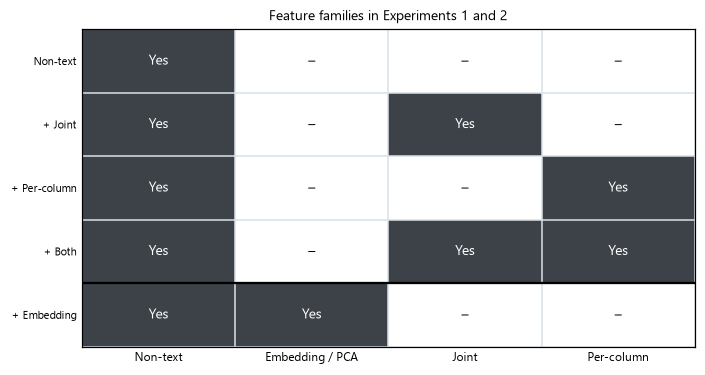

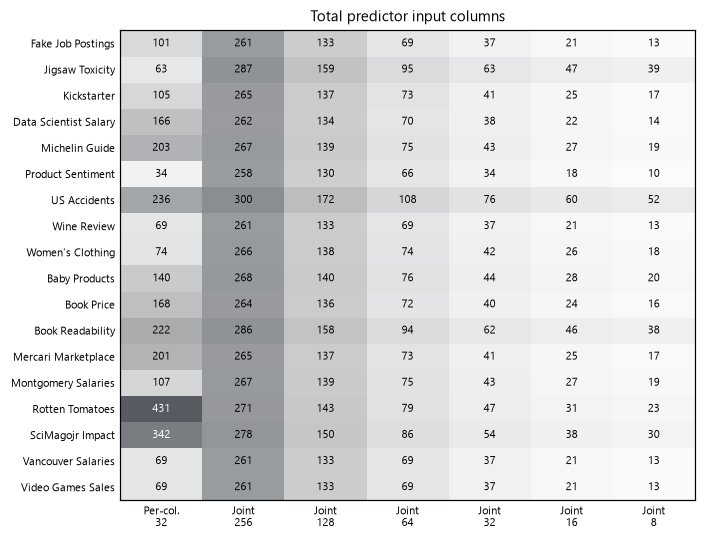

experiment,datasets,predictors,configurations,outer_fits,binary_inner_fits
experiment_1,18,6,3672,18360,9180
experiment_2,18,6,2268,11340,5670
experiment_3,18,3,54,270,135


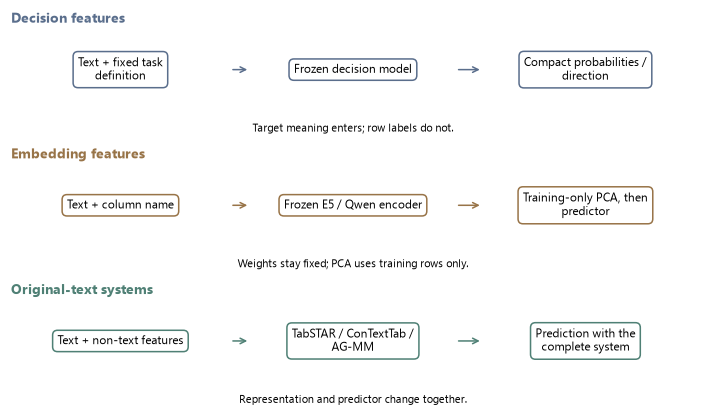

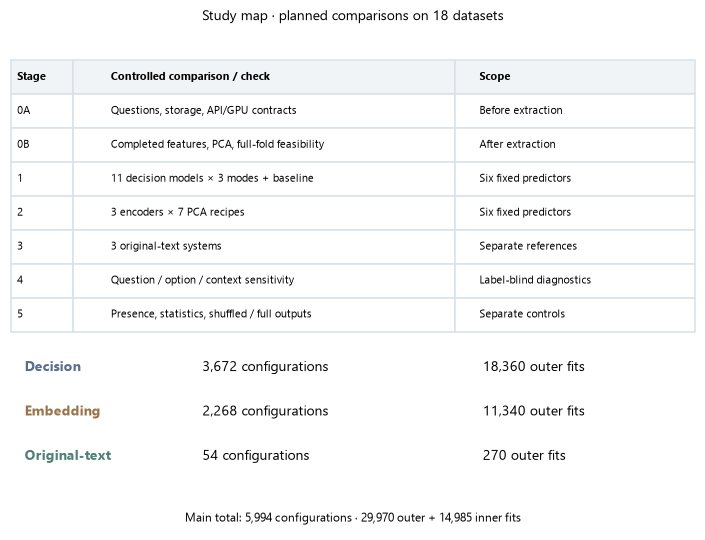

In [7]:
report_section("6. Feature families, experiment sizes and width feasibility")
from src.evaluation.features import benchmark_feature_table
from src.visualize.feature_design import benchmark_configurations_figure
from src.evaluation.campaign import benchmark_plan
configuration_table = benchmark_feature_table()
display_local(configuration_table)
fig, name, caption = benchmark_configurations_figure(configuration_table)
save(fig, name, caption=caption)
display_local(fig)
plt.close(fig)
benchmark = pd.DataFrame(benchmark_plan())
record(benchmark.groupby(["phase", "model", "feature_set"], dropna=False).size().rename("dataset_extractor_configurations").reset_index(), "Complete benchmark configuration counts")
record({"configurations": len(benchmark), "outer_fits": 5 * len(benchmark), "binary_inner_fits": "Three additional fits per outer fold", "PCA_fit_scope": "Each inner/outer training partition only", "raw_embedding_caches": "data/text_embeddings/<dataset>.sqlite3 (small E5); <encoder>/<dataset>.sqlite3 for large E5 and Qwen", "GPU_execution": "Pending real runtime checks"}, "Benchmark scope")
record(benchmark.groupby(["phase", "width_status"]).size().rename("configurations").reset_index(), "Width feasibility by experiment")
record(benchmark.loc[benchmark.width_status.eq("unsupported_width"), ["dataset_id", "model", "pca_components", "pca_scope", "predictor_columns", "recipe_column_limit"]].drop_duplicates().sort_values(["dataset_id", "predictor_columns"]), "Unsupported configurations: no silent column removal")
record(load_yaml("feature_creation/embedding_models")["models"], "Frozen encoder pins and pooling recipes")

from src.evaluation.widths import pca_width_table
from src.visualize.feature_design import pca_width_figure
widths = pca_width_table()
record(widths, "All dataset PCA widths including non-text and missing indicators")
fig, name, caption = pca_width_figure(widths)
save(fig, name, caption=caption)
display_local(fig)
plt.close(fig)

from src.evaluation.notebook_evidence import study_grid
from src.visualize.research import representation_families_figure, study_grid_figure
grid = study_grid(benchmark.to_dict("records"))
display_local(grid)
for fig, name, caption in (representation_families_figure(), study_grid_figure(grid)):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)
record("Experiments 1–3 are the main representation comparisons. Experiment 5 controls and optional "
       "concatenations are counted separately; selected-winner combinations remain exploratory. "
       "Full-fold feasibility, fitted PCA rank and training-only explained variance need actual "
       "completed preprocessing/fit artifacts. No explained-variance or efficacy curve is invented here.",
       "Planned versus measured scientific evidence")


## Complete review report

In [8]:
finish_report(NOTEBOOK, f"""{len(scope)} datasets selected; Zomato and Spotify audit-only, removed from extraction and experiments.
{int(central.unique_requests):,} unique requests for both modes; approximately {int(central.input_tokens_approx):,} input tokens; central cost {central.cost_usd} USD.
Permanent responses/features are stored separately from the shared prepared inputs. Logs go to output_JEVPFN/2. feature_creation/logs.
""" + save.summary())

2. feature_creation/03_feature_creation

1. The selected dataset and feature scope

              dataset                 task_type   rows  text_columns  per_column  joint  main_features_both  combined_unique_inputs
    Fake Job Postings     binary_classification  12725             3           3      1                   4                   34631
      Jigsaw Toxicity     binary_classification 100000             1           1      1                   1                   99661
          Kickstarter     binary_classification  86502             3           3      1                   4                  345321
Data Scientist Salary multiclass_classification  15841             5          30      6                  36                   42668
       Michelin Guide multiclass_classification  18843             6          30      5                  35                   82599
    Product Sentiment multiclass_classification   5091             1           4      4                   4                 